# ItemCF 基线、Precision 与推荐诊断

本 Notebook 展示正反馈 ItemCF 的验证选参、最终测试、Precision/Recall/NDCG、平均命中部数、命中用户比例，以及数据与评分审计。

先运行 `python train.py --model itemcf`，再运行 `python audit_itemcf.py`。Notebook 读取保存结果，不会自动重新调参或测试；修改用户 ID 可生成新的推荐。

In [1]:
from pathlib import Path
import json
import sys

import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import pandas as pd
from IPython.display import Markdown, display

PROJECT_ROOT = next((path for path in [Path.cwd(), *Path.cwd().parents]
                     if (path / 'src' / 'models' / 'item_cf.py').is_file()), None)
if PROJECT_ROOT is None:
    raise RuntimeError('请从项目根目录或 notebooks 目录启动。')
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.recommend import file_sha256, recommend_for_user

%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid')
TABLE_DIR = PROJECT_ROOT / 'outputs' / 'tables'
MODEL_DIR = PROJECT_ROOT / 'outputs' / 'models' / 'itemcf'
PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
FIGURE_DIR = PROJECT_ROOT / 'outputs' / 'figures'
print(f'Project: {PROJECT_ROOT}')

Project: E:\港城莞\课程资料\研一 SemA\CS5481 Data Engineer\data_engineer_group_project


## 1. 算法原理与选定配置

训练输入是评分至少 4 分的二值正反馈矩阵 $B$。电影共现矩阵为 $C=B^TB$，电影支持数为 $f_i=C_{ii}$。对存在共现的不同电影计算：

$$s_{ij}=\frac{C_{ij}}{\sqrt{f_i f_j}}\frac{C_{ij}}{C_{ij}+\lambda}.$$

$\lambda=0$ 时为普通余弦相似度。自身相似度设为 0；每部来源电影仅保留最相似的 $K$ 个邻居，因此最终邻居矩阵可能不对称。候选电影分数为：

$$score(u,j)=\sum_{i\in H_u^+}s_{ij}.$$

$H_u^+$ 是推荐时允许看到的正反馈历史。该分数用于排序，不是 1–5 分的预测。低分电影仍在已评分过滤历史中。

这里的邻居数 $K$ 与“推荐前 5/10 部电影”的截断数量是两个不同参数。相似度完全根据训练集拟合，电影类型和人口属性不参与该基线。

In [2]:
run_path = TABLE_DIR / 'itemcf_run.json'
if not run_path.is_file() or not (MODEL_DIR / 'run.json').is_file():
    raise FileNotFoundError('请先运行 python train.py --model itemcf。')
run = json.loads(run_path.read_text(encoding='utf-8'))
for filename, checksum in run['input_sha256'].items():
    if file_sha256(PROCESSED_DIR / filename) != checksum:
        raise ValueError(f'预处理输入已变化：{filename}；请重新运行基线。')
display(pd.DataFrame([run['selected_parameters']]))
display(Markdown(
    f'**选定方式：**{run["selection_metric"]}。选定邻居数为 '
    f'**{run["selected_parameters"]["n_neighbors"]}**，收缩参数为 '
    f'**{run["selected_parameters"]["shrinkage"]:g}**。'
    f'选定参数这一次拟合耗时 **{run["fit_seconds_selected_trial"]:.2f} 秒**，'
    '模型参数未使用验证或测试交互拟合。'
))

,n_neighbors,shrinkage
0,50,0.0


**选定方式：**NDCG@10 on validation。选定邻居数为 **50**，收缩参数为 **0**。选定参数这一次拟合耗时 **1.58 秒**，模型参数未使用验证或测试交互拟合。

## 2. 验证集参数搜索

默认比较 3 种邻居数量和 3 种收缩参数，共 9 个配置。主选择指标为验证 NDCG@10；同分时依次比较 Recall@10、较小邻居数和较小收缩参数。所有配置使用同一验证用户与完整候选规则。测试集不参与这些选择。

,n_neighbors,shrinkage,fit_seconds,validation_seconds,users,MeanHits@5,Precision@5,HitRate@5,Recall@5,NDCG@5,CatalogCoverage@5,MeanHits@10,Precision@10,HitRate@10,Recall@10,NDCG@10,CatalogCoverage@10,selected
0,20,0.000000,0.73,2.27,5776,0.341586,6.83%,0.242555,0.0470,0.0769,0.107172,0.604224,6.04%,0.352666,0.0825,0.0842,0.156804,False
1,20,10.000000,1.96,5.35,5776,0.337777,6.76%,0.236150,0.0453,0.0765,0.080720,0.599377,5.99%,0.348684,0.0801,0.0835,0.116171,False
2,20,50.000000,1.97,4.48,5776,0.324792,6.50%,0.225935,0.0428,0.0735,0.054268,0.587777,5.88%,0.339335,0.0762,0.0805,0.080175,False
3,50,0.000000,1.58,5.53,5776,0.337777,6.76%,0.233553,0.0457,0.0782,0.094082,0.596607,5.97%,0.344529,0.0789,0.0844,0.131443,True
4,50,10.000000,1.82,4.94,5776,0.337084,6.74%,0.230263,0.0445,0.0767,0.063812,0.596087,5.96%,0.339855,0.0770,0.0827,0.092446,False
5,50,50.000000,1.87,5.44,5776,0.318906,6.38%,0.218144,0.0403,0.0722,0.042542,0.579640,5.80%,0.332583,0.0734,0.0790,0.060813,False
6,100,0.000000,1.88,5.67,5776,0.338123,6.76%,0.234765,0.0448,0.0771,0.078538,0.595222,5.95%,0.338123,0.0774,0.0831,0.113172,False
7,100,10.000000,0.90,2.13,5776,0.335873,6.72%,0.232514,0.0438,0.0756,0.054540,0.590374,5.90%,0.336392,0.0755,0.0812,0.075811,False
8,100,50.000000,0.80,2.08,5776,0.321676,6.43%,0.221434,0.0407,0.0729,0.041996,0.575831,5.76%,0.330332,0.0728,0.0789,0.055631,False


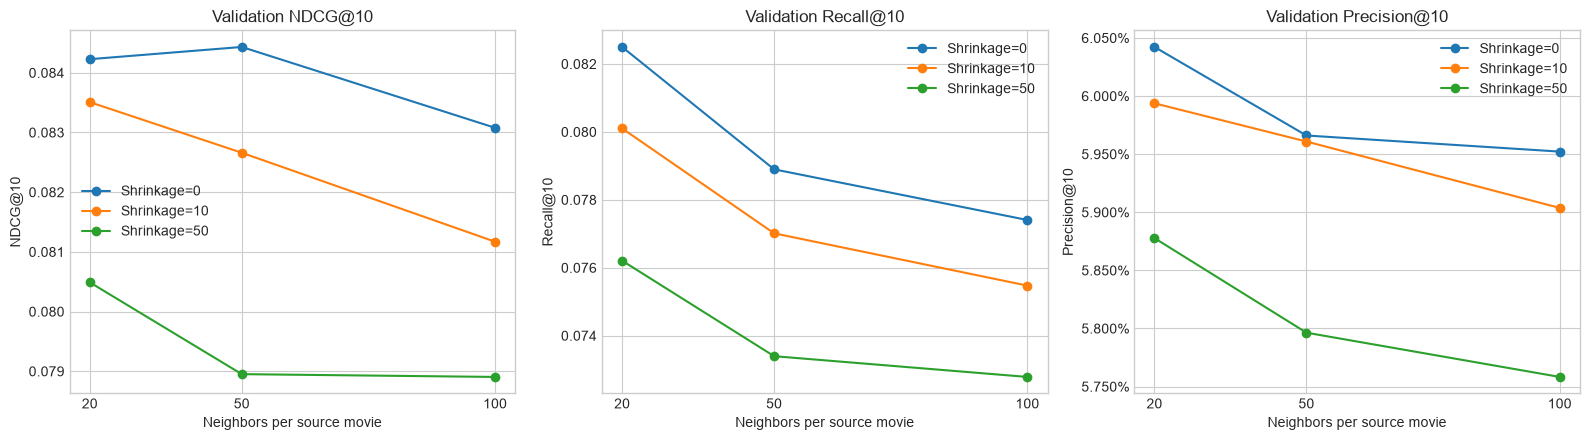

In [3]:
search = pd.read_csv(TABLE_DIR / 'itemcf_validation_search.csv')
display(search.style.format({'Recall@5': '{:.4f}', 'NDCG@5': '{:.4f}',
                            'Recall@10': '{:.4f}', 'NDCG@10': '{:.4f}',
                            'Precision@5': '{:.2%}', 'Precision@10': '{:.2%}',
                            'fit_seconds': '{:.2f}', 'validation_seconds': '{:.2f}'}))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for shrinkage, group in search.groupby('shrinkage', sort=True):
    group = group.sort_values('n_neighbors')
    for ax, metric in zip(axes, ['NDCG@10', 'Recall@10', 'Precision@10']):
        ax.plot(group['n_neighbors'], group[metric], marker='o', label=f'Shrinkage={shrinkage:g}')
        ax.set(xlabel='Neighbors per source movie', ylabel=metric, title=f'Validation {metric}')
        ax.set_xticks(sorted(search['n_neighbors'].unique()))
        if metric == 'Precision@10':
            ax.yaxis.set_major_formatter(PercentFormatter(1))
        ax.legend()
fig.tight_layout()
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(FIGURE_DIR / '09_itemcf_validation_search.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

## 3. 选定模型的验证与测试表现

所有指标共用完整候选：训练目录减去用户当时已评分的电影。同分按原始电影 ID 升序排列，零支持候选为零分。

- **Precision@K**：前 K 部推荐中命中的已知正例数除以 K，直接回答这张推荐列表有多少已知命中。
- **MeanHits@K**：每位用户前 K 部推荐的平均命中部数，等于 K × Precision@K。
- **HitRate@K**：前 K 部中至少命中一部的用户比例。
- **Recall@K**：命中数除以该用户全部可评估正例数。
- **NDCG@K**：命中位置越靠前贡献越大，再按理想排序归一化。
- **CatalogCoverage@K**：所有用户被推荐到的不同电影数占训练目录的比例。

Precision、Recall、NDCG 均逐用户计算再宏平均。未评分电影在这些离线指标中不计为命中，但其真实偏好未知。

Top-5/10 是本项目的实验设置。验证使用训练历史，测试使用训练加验证历史，模型相似度固定由训练集拟合。此次补充指标保留已有验证 NDCG@10 的选参规则，不根据已看过的测试结果改变参数。

In [4]:
metrics = pd.read_csv(TABLE_DIR / 'itemcf_metrics.csv')
metric_columns = [column for column in metrics if '@' in column]
formats = {column: '{:.4f}' for column in metric_columns}
for column in metric_columns:
    if column.startswith(('Precision@', 'HitRate@', 'CatalogCoverage@')):
        formats[column] = '{:.2%}'
    elif column.startswith('MeanHits@'):
        formats[column] = '{:.3f}'
display(metrics.style.format(formats))
test_metrics = metrics.set_index('split').loc['test']
display(Markdown(
    f'**测试结果：**在 **{int(test_metrics["users"]):,}** 位共同可评估用户上，'
    f'Precision@10 为 **{test_metrics["Precision@10"]:.2%}**，平均每位用户命中 '
    f'**{test_metrics["MeanHits@10"]:.3f}** 部，至少命中一部的用户占 '
    f'**{test_metrics["HitRate@10"]:.2%}**。'
    f'Recall@10 为 **{test_metrics["Recall@10"]:.4f}**，NDCG@10 为 '
    f'**{test_metrics["NDCG@10"]:.4f}**。这些结果只覆盖共享可评估用户与训练目录内正例。'
))

,algorithm,split,users,MeanHits@5,Precision@5,HitRate@5,Recall@5,NDCG@5,CatalogCoverage@5,MeanHits@10,Precision@10,HitRate@10,Recall@10,NDCG@10,CatalogCoverage@10
0,ItemCF,validation,5776,0.338,6.76%,23.36%,0.0457,0.0782,9.41%,0.597,5.97%,34.45%,0.0789,0.0844,13.14%
1,ItemCF,test,5765,0.324,6.47%,22.78%,0.0414,0.0729,8.48%,0.564,5.64%,33.24%,0.0712,0.0773,12.63%


**测试结果：**在 **5,765** 位共同可评估用户上，Precision@10 为 **5.64%**，平均每位用户命中 **0.564** 部，至少命中一部的用户占 **33.24%**。Recall@10 为 **0.0712**，NDCG@10 为 **0.0773**。这些结果只覆盖共享可评估用户与训练目录内正例。

## 4. 每张推荐列表实际命中了几部？

使用逐用户的整数 `Hits@10` 查看分布，并区分“平均命中数量”“推荐列表 Precision”和“至少命中一部的用户比例”。这三个数字含义不同。

,relevant_items,candidate_count,Hits@10,Precision@10,Recall@10,NDCG@10
count,5765.0000,5765.0000,5765.0000,5765.0000,5765.0000,5765.0000
mean,8.9709,3513.7056,0.5641,0.0564,0.0712,0.0773
std,9.8512,175.6879,1.0125,0.1013,0.1527,0.1449
min,1.0000,1586.0000,0.0000,0.0000,0.0000,0.0000
25%,3.0000,3475.0000,0.0000,0.0000,0.0000,0.0000
50%,6.0000,3577.0000,0.0000,0.0000,0.0000,0.0000
75%,11.0000,3625.0000,1.0000,0.1000,0.0833,0.1070
max,117.0000,3655.0000,9.0000,0.9000,1.0000,1.0000


,hits,users,share
6,0,3849,66.76%
7,1,1143,19.83%
8,2,434,7.53%
9,3,197,3.42%
10,4,87,1.51%
11,5,38,0.66%
12,6,10,0.17%
13,7,5,0.09%
14,8,1,0.02%
15,9,1,0.02%


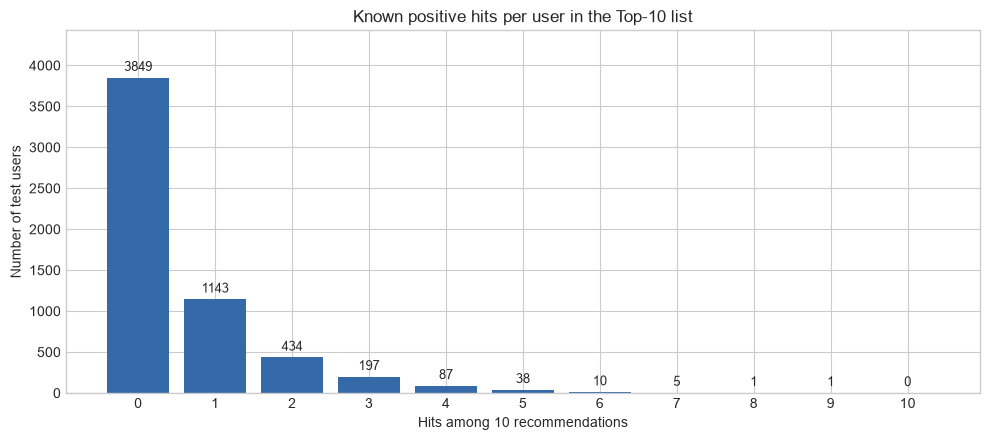

**命中观察：**共有 **3,849 / 5,765** 位测试用户（**66.76%**）在 Top-10 中没有已知正例命中。下面进一步检查推荐中已知低分与未观察评分的比例，避免把未命中全部解释为不喜欢。

In [5]:
per_user = pd.read_csv(MODEL_DIR / 'test_per_user.csv')
zero_hit_users = int(per_user['Hits@10'].eq(0).sum())
display(per_user[['relevant_items', 'candidate_count', 'Hits@10', 'Precision@10', 'Recall@10', 'NDCG@10']]
        .describe().round(4))
distribution_path = TABLE_DIR / 'itemcf_hit_distribution.csv'
if not distribution_path.is_file():
    raise FileNotFoundError('请先运行 python audit_itemcf.py。')
hit_distribution = pd.read_csv(distribution_path)
hit_distribution = hit_distribution.loc[hit_distribution['k'].eq(10)]
display(hit_distribution[['hits', 'users', 'share']].style.format({'share': '{:.2%}'}))
fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(hit_distribution['hits'], hit_distribution['users'], color='#3569a8')
ax.bar_label(bars, padding=3, fontsize=9)
ax.set(title='Known positive hits per user in the Top-10 list',
       xlabel='Hits among 10 recommendations', ylabel='Number of test users')
ax.set_xticks(range(11))
ax.margins(y=0.15)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '10_itemcf_hit_distribution.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)
display(Markdown(
    f'**命中观察：**共有 **{zero_hit_users:,} / {len(per_user):,}** 位测试用户'
    f'（**{zero_hit_users / len(per_user):.2%}**）在 Top-10 中没有已知正例命中。'
    '下面进一步检查推荐中已知低分与未观察评分的比例，避免把未命中全部解释为不喜欢。'
))

## 5. 排查低 Precision：实现检查与观测范围

审计程序独立检查 ID 映射、评分标签、稀疏矩阵、真实数据上抽样的余弦相似度与邻居方向、历史 token、候选过滤、可评估正例和 Precision 计数。检查通过说明这些具体环节未发现不一致，不能保证该 ItemCF 变体最优。

推荐分成三类：留出期评分达到阈值、留出期已评分但低于阈值、留出期没有评分。第三类真实偏好未知，离线 Precision 将其记为未命中。诊断表不把仅在“有评分推荐”上算的高分比例替换为真实 Precision。

热门排序仅作为验证集诊断参照，使用训练期正反馈次数；不参与三个项目算法的选型或测试集调参。

,check,violations
0,input_checksum_mismatches,0
1,source_file_checksum_mismatches,0
2,source_rating_rows_mismatched,0
3,source_row_count_not_explained_by_cleaning,0
4,train_label_mismatches,0
5,validation_label_mismatches,0
6,test_label_mismatches,0
7,explicit_matrix_entries_mismatched,0
8,positive_matrix_entries_mismatched,0
9,similarity_diagonal_nonzeros,0


,stage,recommendations,share,mean_per_user
category,,,,
heldout_rating_4_or_5,test,3252,5.64%,0.564
heldout_rating_1_to_3,test,728,1.26%,0.126
no_heldout_rating,test,53670,93.10%,9.310


stage,validation,test
users,5776.0000,5765.0000
mean_candidate_count,3530.9517,3513.7056
mean_observed_positive_targets,9.2677,8.9709
users_with_one_observed_positive,532.0000,532.0000
users_with_fewer_than_10_observed_positives,3938.0000,3995.0000
mean_observable_precision_ceiling_at_10,0.6010,0.5943
zero_score_top10_slots,0.0000,0.0000
mean_nonzero_score_candidates,583.0866,618.5325
mean_training_support_recommended,1542.5208,1532.1602
mean_training_support_unseen_candidates,114.0243,112.6523


,method,split,Precision@10,MeanHits@10,Recall@10,NDCG@10
0,TrainingPopularityDiagnostic,validation,4.53%,0.453,0.0482,0.0578
1,ItemCF,validation,5.97%,0.597,0.0789,0.0844


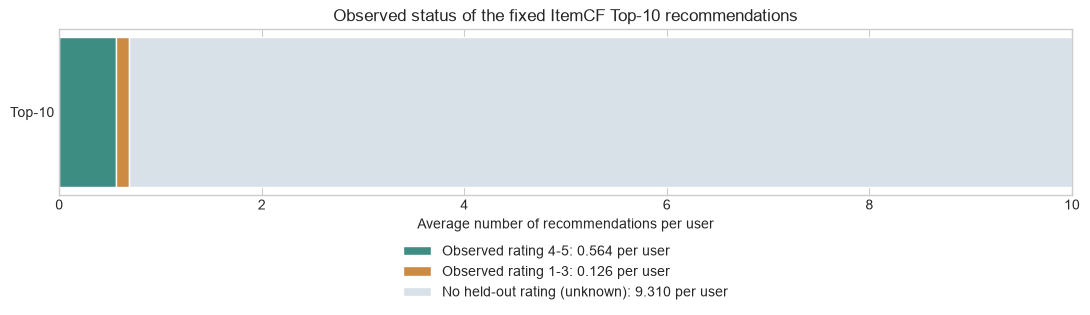

**诊断结果：**共 **32** 项完整性检查为 0 违规。推荐中 **93.10%** 在测试期没有评分记录，**1.26%** 有 1–3 分记录。进入 Top-10 的零分候选共有 **0** 个。因此，Precision 的剩余部分需要按上述观测状态解释；这不能证明未知电影会被喜欢，也不能把所有未知电影都判为用户不喜欢。

In [6]:
integrity = pd.read_csv(TABLE_DIR / 'itemcf_integrity_checks.csv')
assert not integrity['violations'].any()
display(integrity)
status = pd.read_csv(TABLE_DIR / 'itemcf_recommendation_status.csv')
test_status = status.loc[status['stage'].eq('test')].set_index('category')
display(test_status.style.format({'share': '{:.2%}', 'mean_per_user': '{:.3f}'}))
scope = pd.read_csv(TABLE_DIR / 'itemcf_evaluation_scope.csv').set_index('stage')
display(scope.T.round(4))
reference = pd.read_csv(TABLE_DIR / 'itemcf_validation_reference.csv')
display(reference[['method', 'split', 'Precision@10', 'MeanHits@10', 'Recall@10', 'NDCG@10']]
        .style.format({'Precision@10': '{:.2%}', 'MeanHits@10': '{:.3f}',
                       'Recall@10': '{:.4f}', 'NDCG@10': '{:.4f}'}))

labels = ['Observed rating 4-5', 'Observed rating 1-3', 'No held-out rating (unknown)']
categories = ['heldout_rating_4_or_5', 'heldout_rating_1_to_3', 'no_heldout_rating']
colors = ['#3d8d83', '#cc8a43', '#d9e1e8']
fig, ax = plt.subplots(figsize=(11, 3.5))
left = 0
for category, label, color in zip(categories, labels, colors):
    value = float(test_status.loc[category, 'mean_per_user'])
    ax.barh(['Top-10'], [value], left=left, color=color,
            label=f'{label}: {value:.3f} per user', edgecolor='white')
    left += value
ax.set(title='Observed status of the fixed ItemCF Top-10 recommendations',
       xlabel='Average number of recommendations per user', xlim=(0, 10))
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.23), ncol=1)
fig.tight_layout()
fig.savefig(FIGURE_DIR / '11_itemcf_recommendation_status.png', dpi=180, bbox_inches='tight')
plt.show()
plt.close(fig)

unknown_share = float(test_status.loc['no_heldout_rating', 'share'])
low_share = float(test_status.loc['heldout_rating_1_to_3', 'share'])
display(Markdown(
    f'**诊断结果：**共 **{len(integrity)}** 项完整性检查为 0 违规。'
    f'推荐中 **{unknown_share:.2%}** 在测试期没有评分记录，'
    f'**{low_share:.2%}** 有 1–3 分记录。'
    f'进入 Top-10 的零分候选共有 **{int(scope.loc["test", "zero_score_top10_slots"]):,}** 个。'
    '因此，Precision 的剩余部分需要按上述观测状态解释；'
    '这不能证明未知电影会被喜欢，也不能把所有未知电影都判为用户不喜欢。'
))

## 6. 按用户 ID 生成推荐

修改 `USER_ID`、`TOP_K` 后重新运行下面的单元格。`HISTORY_STAGE='test'` 使用测试期开始前的已知历史；`'validation'` 只使用训练历史。这是离线数据的推荐演示。

`because_title` 为贡献最大的已知喜欢电影，`because_similarity` 为其保留的相似度贡献；总推荐分数还可能累加其他历史电影的贡献。已评分电影全部过滤，标题与类型从电影元数据读取。

In [7]:
USER_ID = 1
TOP_K = 10
HISTORY_STAGE = 'test'

recommendations = recommend_for_user(USER_ID, stage=HISTORY_STAGE, k=TOP_K)
display(recommendations[['rank', 'title', 'genres', 'score', 'because_title', 'because_similarity']]
        .style.format({'score': '{:.4f}', 'because_similarity': '{:.4f}'}))
print(f'User {USER_ID}: {len(recommendations)} unseen movie recommendations')

,rank,title,genres,score,because_title,because_similarity
0,1,Raiders of the Lost Ark (1981),Action|Adventure,10.8170,Star Wars: Episode IV - A New Hope (1977),0.6487
1,2,Star Wars: Episode V - The Empire Strikes Back (1980),Action|Adventure|Drama|Sci-Fi|War,10.2634,Star Wars: Episode IV - A New Hope (1977),0.7289
2,3,"Shawshank Redemption, The (1994)",Drama,9.5549,Schindler's List (1993),0.6051
3,4,"Silence of the Lambs, The (1991)",Drama|Thriller,8.4180,Fargo (1996),0.5792
4,5,Pulp Fiction (1994),Crime|Drama,6.7816,Fargo (1996),0.6188
5,6,American Beauty (1999),Comedy|Drama,6.4808,Fargo (1996),0.5260
6,7,Groundhog Day (1993),Comedy|Romance,6.3872,Toy Story (1995),0.4916
7,8,Stand by Me (1986),Adventure|Comedy|Drama,6.3493,Ferris Bueller's Day Off (1986),0.4551
8,9,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War,6.2726,Star Wars: Episode IV - A New Hope (1977),0.6435
9,10,Shakespeare in Love (1998),Comedy|Romance,6.0314,"Sixth Sense, The (1999)",0.4387


User 1: 10 unseen movie recommendations


## 7. 固定用户案例与后续比较

下表按用户 ID 顺序选择前三位可评估测试用户，每人推荐 10 部电影，未按命中结果挑选用户。`relevant_in_test` 仅用于结果分析，在推荐分数计算完成后添加，不输入模型。

In [8]:
examples = pd.read_csv(TABLE_DIR / 'itemcf_recommendation_examples.csv')
display(examples[['user_id', 'rank', 'title', 'genres', 'because_title', 'relevant_in_test']])
example_hits = examples.groupby('user_id')['relevant_in_test'].sum().to_frame('hits_in_top10')
display(example_hits)

,user_id,rank,title,genres,because_title,relevant_in_test
0,1,1,Raiders of the Lost Ark (1981),Action|Adventure,Star Wars: Episode IV - A New Hope (1977),False
1,1,2,Star Wars: Episode V - The Empire Strikes Back...,Action|Adventure|Drama|Sci-Fi|War,Star Wars: Episode IV - A New Hope (1977),False
2,1,3,"Shawshank Redemption, The (1994)",Drama,Schindler's List (1993),False
3,1,4,"Silence of the Lambs, The (1991)",Drama|Thriller,Fargo (1996),False
4,1,5,Pulp Fiction (1994),Crime|Drama,Fargo (1996),False
5,1,6,American Beauty (1999),Comedy|Drama,Fargo (1996),False
6,1,7,Groundhog Day (1993),Comedy|Romance,Toy Story (1995),False
7,1,8,Stand by Me (1986),Adventure|Comedy|Drama,Ferris Bueller's Day Off (1986),False
8,1,9,Star Wars: Episode VI - Return of the Jedi (1983),Action|Adventure|Romance|Sci-Fi|War,Star Wars: Episode IV - A New Hope (1977),False
9,1,10,Shakespeare in Love (1998),Comedy|Romance,"Sixth Sense, The (1999)",False


,hits_in_top10
user_id,
1,0
2,0
3,0


本阶段已经跑通第一种推荐算法。后续算法复用同一数据划分、用户集合、候选和指标，模型选择继续依据验证集。

算法参考：Badrul Sarwar, George Karypis, Joseph Konstan, and John Riedl. 2001. [Item-based Collaborative Filtering Recommendation Algorithms](https://ra.ethz.ch/cdstore/www10/papers/519/sdm2.html)。本项目使用正反馈二值输入、可选相似度收缩和统一 Top-N 协议的具体实现。